# Phytoplankton experiment

## Visualize

Dataset composition and sample crops for the binary *phytoplankton vs not*
task. Expects `pre_process_data.ipynb` to have populated
`Processed_data/<raw class>/` and uses the label map in
`phytoplankton/scripts/constants.py`.

In [1]:
import os
import sys
import glob
import random

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

sys.path.insert(0, os.path.abspath(os.path.join('..', 'scripts')))
import constants as C

PROCESSED_DIR = '/data/Hier-Phytoplankton/Processed_data'
IMG_GLOB = '*.tif'
SEED = 0

# raw-class bucket (constants.CLASS_MAP value) -> label shown in the charts
DISPLAY_BUCKET = {
    'Phytoplankton':     'Phytoplankton',
    'Not Phytoplankton': 'Not Phytoplankton',
    C.TBD:               'Others (TBD)',
    C.EXCLUDE:           'Excluded (duplicates)',
}


def image_counts(processed_dir=PROCESSED_DIR):
    """raw CSV class -> number of cropped images on disk."""
    return {raw: len(glob.glob(os.path.join(processed_dir, raw, IMG_GLOB)))
            for raw in C.CLASS_MAP}


counts = image_counts()
print(f'{sum(counts.values()):,} images across {len(counts)} raw classes')

9,920 images across 24 raw classes


### Composition: phytoplankton vs not phytoplankton vs others (TBD)

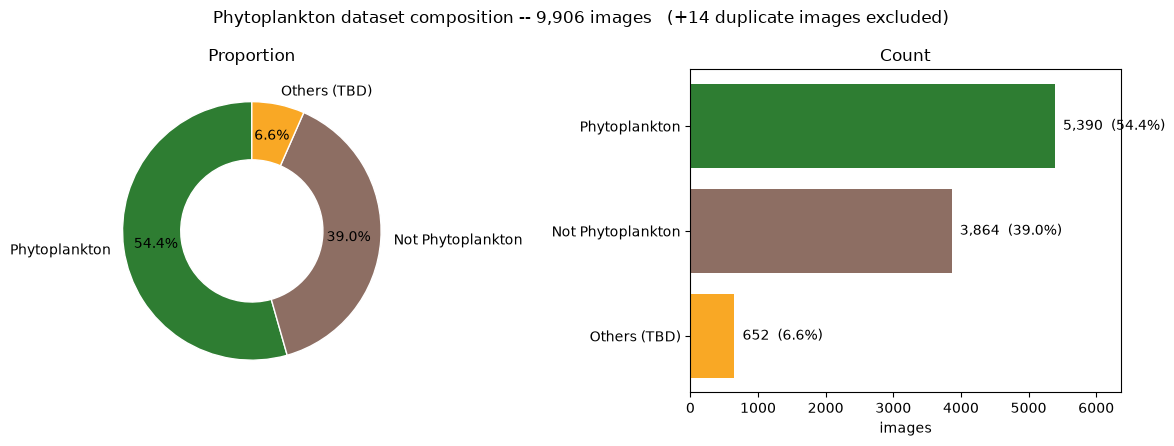

Phytoplankton         5,390    54.4%
Not Phytoplankton     3,864    39.0%
Others (TBD)            652     6.6%


In [2]:
# Aggregate the per-raw-class image counts into the three groups of interest.
# Duplicate / Duplicates are dropped from the model entirely -- reported only as
# a footnote here, not drawn.
GROUPS = ['Phytoplankton', 'Not Phytoplankton', 'Others (TBD)']
COLORS = {'Phytoplankton': '#2e7d32',        # green
          'Not Phytoplankton': '#8d6e63',    # brown
          'Others (TBD)': '#f9a825'}          # amber

group_counts = dict.fromkeys(GROUPS, 0)
n_excluded = 0
for raw, n in counts.items():
    label = DISPLAY_BUCKET[C.CLASS_MAP[raw]]
    if label in group_counts:
        group_counts[label] += n
    else:
        n_excluded += n

total = sum(group_counts.values())
vals = [group_counts[g] for g in GROUPS]
cols = [COLORS[g] for g in GROUPS]

fig, (ax_pie, ax_bar) = plt.subplots(1, 2, figsize=(12, 4.5))

ax_pie.pie(vals, labels=GROUPS, colors=cols, startangle=90,
           autopct='%1.1f%%', pctdistance=0.75,
           wedgeprops=dict(width=0.45, edgecolor='white'))
ax_pie.set_title('Proportion')

y = np.arange(len(GROUPS))[::-1]
ax_bar.barh(y, vals, color=cols)
ax_bar.set_yticks(y, GROUPS)
ax_bar.set_xlabel('images')
ax_bar.set_title('Count')
for yi, v in zip(y, vals):
    ax_bar.text(v, yi, f'  {v:,}  ({v / total:.1%})', va='center')
ax_bar.margins(x=0.18)

footnote = f'   (+{n_excluded} duplicate images excluded)' if n_excluded else ''
fig.suptitle(f'Phytoplankton dataset composition -- {total:,} images{footnote}')
fig.tight_layout()
plt.show()

for g in GROUPS:
    print(f'{g:<20s} {group_counts[g]:>6,d}   {group_counts[g] / total:>6.1%}')

### Sample crops

Five phytoplankton (top row) and five non-phytoplankton (bottom row), each drawn
from a different raw category where possible; the caption is the raw category.
Non-phytoplankton has only four raw categories, so one repeats. Change `SEED` for
a different draw.

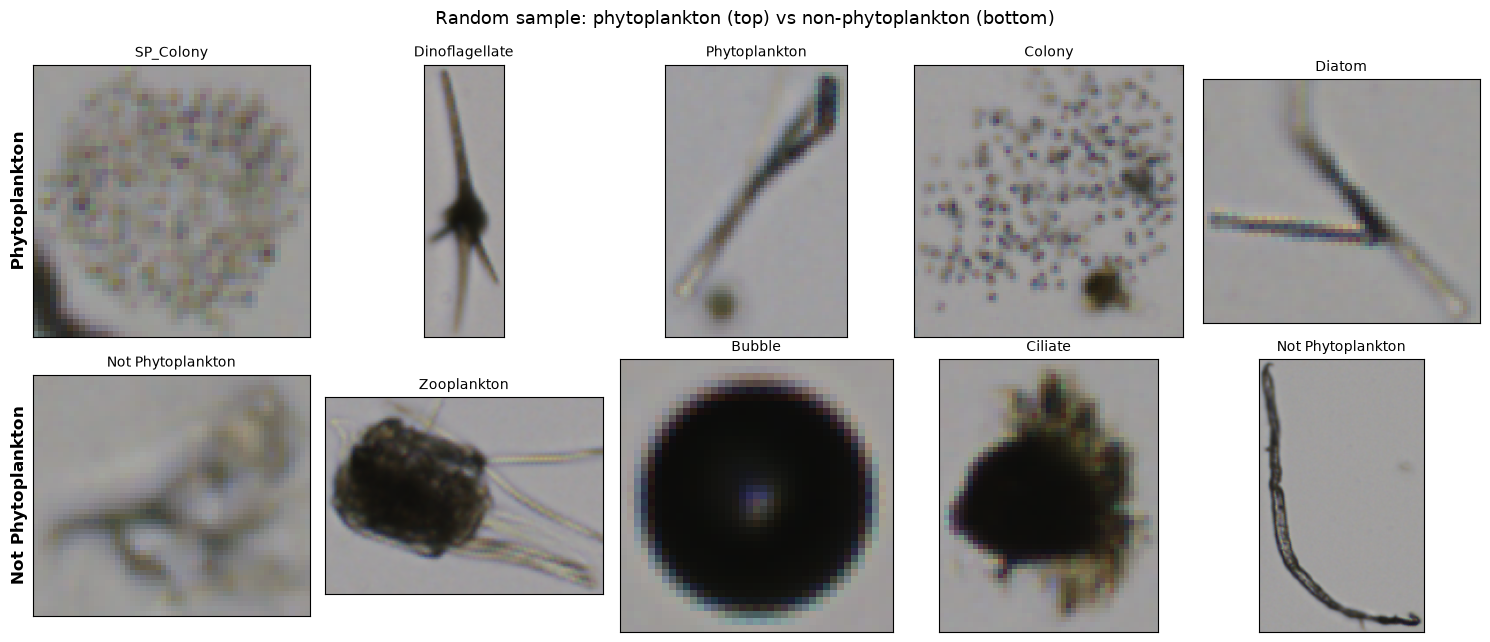

In [3]:
rng = random.Random(SEED)


def sample_from_bucket(model_class, n=5):
    """Return n (raw_category, image_path), preferring distinct raw categories."""
    cats = [c for c in C.BINARY_CLASS_FOLDERS[model_class]
            if glob.glob(os.path.join(PROCESSED_DIR, c, IMG_GLOB))]
    picked = rng.sample(cats, min(n, len(cats)))
    while len(picked) < n:                      # fewer categories than columns
        picked.append(rng.choice(cats))
    return [(c, rng.choice(glob.glob(os.path.join(PROCESSED_DIR, c, IMG_GLOB))))
            for c in picked]


ROWS = ['Phytoplankton', 'Not Phytoplankton']
N_COLS = 5
fig, axes = plt.subplots(len(ROWS), N_COLS, figsize=(15, 6.5))

for r, model_class in enumerate(ROWS):
    for c, (category, path) in enumerate(sample_from_bucket(model_class, N_COLS)):
        ax = axes[r, c]
        ax.imshow(np.asarray(Image.open(path)))
        ax.set_title(category, fontsize=10)
        ax.set_xticks([])
        ax.set_yticks([])
    axes[r, 0].set_ylabel(model_class, fontsize=12, fontweight='bold')

fig.suptitle('Random sample: phytoplankton (top) vs non-phytoplankton (bottom)',
             fontsize=13)
fig.tight_layout()
plt.show()

# Dataloader